Import Libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.utils import to_categorical

Load dataset

In [ ]:
train = pd.read_csv('/Users/ahbiswas/Documents/Data_sets/MINIST_data/mnist_train.csv')
test = pd.read_csv('/Users/ahbiswas/Documents/Data_sets/MINIST_data/mnist_test.csv')

In [ ]:
X_train = train.iloc[:, 1:].values
y_train = train.iloc[:, 0].values

X_test = test.iloc[:, 1:].values
y_test = test.iloc[:, 0].values

In [ ]:
X_train

array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]])

In [ ]:
X_train.shape

(60000, 784)

In [ ]:
np.unique(y_train)

array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9])

Normalize

In [ ]:
# pixel values are in 0-255
X_train = X_train / 255.0
X_test = X_test / 255.0

One-hot encoding

In [ ]:
y_train = to_categorical(y_train, 10) #3 → [0, 0, 0, 1, 0, 0, 0, 0, 0, 0]
y_test = to_categorical(y_test, 10)

Build MLP model

In [ ]:
# Input (784 pixels)
#         ↓
# Dense (128 neurons, ReLU)
#         ↓
# Dense (64 neurons, ReLU)
#         ↓
# Dense (10 neurons, Softmax)
#         ↓
# Output (digit prediction)

model = Sequential([
    Dense(128, activation='relu', input_shape=(784,)),
    Dense(64, activation='relu'),
    Dense(10, activation='softmax')
])

/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/keras/src/layers/core/dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
2026-04-08 08:14:00.815932: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M2
2026-04-08 08:14:00.816562: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 16.00 GB
2026-04-08 08:14:00.816579: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 5.33 GB
2026-04-08 08:14:00.816922: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
2026-04-08 08:14:00.816938: I tensorflow/core/common_runtime/pluggable_device/pluggable_devic

Compile

In [ ]:
# Input → Model → Prediction
#         ↓
# Compare with true label
#         ↓
# Compute LOSS
#         ↓
# Optimizer updates weights
#         ↓
# Repeat (epochs)
model.compile(
    optimizer='adam', #Wrong prediction → calculate error → adjust weights → improve prediction
    loss='categorical_crossentropy', #Measures how wrong the prediction is,Multi-class classification , Labels are one-hot encoded
    metrics=['accuracy'] #Metric → used for evaluation
)

Train

In [ ]:
# Epoch 1:
#   Batch 1 → update weights
#   Batch 2 → update weights
#   ...
# Epoch 2:
#   Repeat again
# ...
# Epoch 10:
#   Final learning
history = model.fit(
    X_train, y_train,
    epochs=10, #Model sees the entire dataset 10 times
    batch_size=32, #Data is split into small chunks of 32 samples
    validation_split=0.1 #10% of training data used for validation
)

Epoch 1/10


2026-04-08 08:14:01.619650: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


1688/1688 ━━━━━━━━━━━━━━━━━━━━ 20s 10ms/step - accuracy: 0.8692 - loss: 0.4817 - val_accuracy: 0.8472 - val_loss: 0.6418
Epoch 2/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 18s 11ms/step - accuracy: 0.8232 - loss: 1.4540 - val_accuracy: 0.7850 - val_loss: 4.2245
Epoch 3/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 18s 11ms/step - accuracy: 0.8044 - loss: 3.3707 - val_accuracy: 0.8060 - val_loss: 4.3603
Epoch 4/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 18s 11ms/step - accuracy: 0.7975 - loss: 5.8518 - val_accuracy: 0.8335 - val_loss: 5.4860
Epoch 5/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 18s 11ms/step - accuracy: 0.7901 - loss: 9.3104 - val_accuracy: 0.7743 - val_loss: 9.5112
Epoch 6/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 18s 11ms/step - accuracy: 0.7861 - loss: 12.9412 - val_accuracy: 0.8585 - val_loss: 7.5198
Epoch 7/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 18s 11ms/step - accuracy: 0.7831 - loss: 17.2484 - val_accuracy: 0.8238 - val_loss: 16.6138
Epoch 8/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 18s 10ms/step - accuracy: 0.7826 - loss: 2

Evaluate

In [ ]:
loss, acc = model.evaluate(X_test, y_test)
print("Test Accuracy:", acc)

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.7794 - loss: 33.0606
Test Accuracy: 0.7793999910354614


Predict From Image

In [ ]:
# pick one sample
sample = X_test[2].reshape(1, 784) #(784,) → (1, 784) ,1 sample, 784 features
prediction = model.predict(sample) #Output is a probability vector
print("Predicted Digit:", np.argmax(prediction))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
Predicted Digit: 1


Visualize Prediction

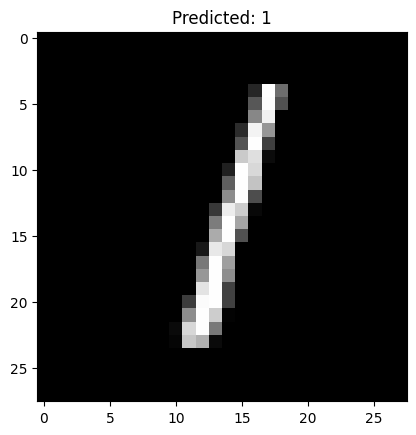

In [ ]:
plt.imshow(X_test[2].reshape(28,28), cmap='gray')
plt.title(f"Predicted: {np.argmax(prediction)}")
plt.show()